## Dataset

**PIC (Paediatric Intensive Care) database** — PhysioNet, v1.1.0
Zeng, X., Yu, G., Lu, Y. *et al.* "PIC, a paediatric-specific intensive care database."
*Scientific Data* 7, 14 (2020). https://doi.org/10.1038/s41597-020-0355-4

- 13,449 hospital admissions / 13,941 ICU stays / 12,881 patients (age 0–18), collected 2010–2018
  at the Children's Hospital of Zhejiang University School of Medicine (5 ICUs: General ICU, PICU,
  SICU, CICU, NICU).

## What this notebook demonstrates (analytics categories we can deliver)

| # | Category | Business value to the hospital |
|---|---|---|
| 1 | Demographics & case-mix | Who are we treating? Informs which sub-specialties to staff/invest in |
| 2 | Demand & seasonality | Admission forecasting → nurse/bed staffing plans |
| 3 | Length-of-stay analytics | Bed-occupancy modeling, cost-per-case, discharge-planning bottlenecks |
| 4 | Outcome / mortality analytics | Quality benchmarking — the credibility backbone of a NICU/PICU brand |
| 5 | Diagnosis / disease burden analytics | Equipment & specialist-panel planning |
| 6 | Readmission & safety indicators | Patient-safety monitoring, a common accreditation KPI |
| 7 | Executive KPI rollup | A leadership-ready one-page scorecard, refreshed on a cadence |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

## 1. Load the real data

We load all four core PIC tables directly as exported from PhysioNet. Two schema quirks worth
noting for anyone extending this pipeline to a hospital's own export:

- **Date formats differ across files** — `ADMISSIONS.csv` uses `DD-MM-YYYY HH:MM`, while
  `ICUSTAYS.csv`/`PATIENTS.csv` use `YYYY-MM-DD HH:MM:SS`. We parse each explicitly.
- **No diagnosis dictionary table was provided** (`D_DIAGNOSES_ICD.csv` — maps ICD-10 codes to
  readable names — wasn't part of this file set). We work directly with `ICD10_CODE_CN` codes and
  group them by **ICD-10 chapter** (the code's leading letter) to keep the diagnosis analysis
  interpretable without the full dictionary. This is exactly the kind of gap-filling step a
  real hospital engagement would need — most hospital EMRs don't ship a clean ICD dictionary either.


In [3]:
admissions = pd.read_csv("ADMISSIONS.csv")
icustays = pd.read_csv("ICUSTAYS.csv")
patients = pd.read_csv("PATIENTS.csv")
diagnoses = pd.read_csv("DIAGNOSES_ICD.csv")

# ADMISSIONS dates: DD-MM-YYYY HH:MM
for col in ["ADMITTIME", "DISCHTIME", "DEATHTIME", "EDREGTIME", "EDOUTTIME"]:
    admissions[col] = pd.to_datetime(admissions[col], format="%d-%m-%Y %H:%M", errors="coerce")

# ICUSTAYS / PATIENTS dates: YYYY-MM-DD HH:MM:SS
for col in ["INTIME", "OUTTIME"]:
    icustays[col] = pd.to_datetime(icustays[col], errors="coerce")
for col in ["DOB", "DOD"]:
    patients[col] = pd.to_datetime(patients[col], errors="coerce")

print(f"admissions:  {admissions.shape}")
print(f"icustays:    {icustays.shape}")
print(f"patients:    {patients.shape}")
print(f"diagnoses:   {diagnoses.shape}")

# Quick referential-integrity check
assert set(icustays["HADM_ID"]) <= set(admissions["HADM_ID"]), "orphan HADM_ID in ICUSTAYS"
assert set(icustays["SUBJECT_ID"]) <= set(patients["SUBJECT_ID"]), "orphan SUBJECT_ID in ICUSTAYS"
assert set(diagnoses["HADM_ID"]) <= set(admissions["HADM_ID"]), "orphan HADM_ID in DIAGNOSES_ICD"
print("\\nReferential integrity: OK — every ICU stay and diagnosis links to a valid admission/patient.")


admissions:  (13449, 18)
icustays:    (13941, 11)
patients:    (12881, 6)
diagnoses:   (13365, 5)
\nReferential integrity: OK — every ICU stay and diagnosis links to a valid admission/patient.


## 2. Build the analysis cohort

One row per ICU stay, joined with admission and patient demographic data, plus derived fields
(age at admission, ICU length of stay, hospital length of stay, age group, admission season).


In [4]:
cohort = (
    icustays
    .merge(admissions, on=["SUBJECT_ID", "HADM_ID"], how="left")
    .merge(patients, on="SUBJECT_ID", how="left")
)

cohort["age_years"] = (cohort["ADMITTIME"] - cohort["DOB"]).dt.days / 365.25
cohort["los_icu_days"] = cohort["LOS"]
cohort["los_hosp_days"] = (cohort["DISCHTIME"] - cohort["ADMITTIME"]).dt.total_seconds() / 86400

def age_group(age):
    if pd.isna(age):
        return "Unknown"
    if age < 1/12:
        return "Neonate (<1mo)"
    elif age < 1:
        return "Infant (1-12mo)"
    elif age < 3:
        return "Toddler (1-3yr)"
    elif age < 12:
        return "Child (3-12yr)"
    else:
        return "Adolescent (12-18yr)"

cohort["age_group"] = cohort["age_years"].apply(age_group)

season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Spring", 4: "Spring", 5: "Spring",
              6: "Summer", 7: "Summer", 8: "Summer",
              9: "Autumn", 10: "Autumn", 11: "Autumn"}
cohort["admit_season"] = cohort["ADMITTIME"].dt.month.map(season_map)

print(f"Cohort built: {len(cohort):,} ICU stays across {cohort['SUBJECT_ID'].nunique():,} patients")
cohort[["SUBJECT_ID", "HADM_ID", "FIRST_CAREUNIT", "age_years", "age_group",
        "los_icu_days", "HOSPITAL_EXPIRE_FLAG"]].head()


Cohort built: 13,941 ICU stays across 12,881 patients


,SUBJECT_ID,HADM_ID,FIRST_CAREUNIT,age_years,age_group,los_icu_days,HOSPITAL_EXPIRE_FLAG
0,26,100000,General ICU,0.383299,Infant (1-12mo),4.6167,0
1,28,100001,General ICU,7.071869,Child (3-12yr),9.1771,1
2,29,100002,General ICU,2.852841,Toddler (1-3yr),7.7326,0
3,30,100003,General ICU,7.791923,Child (3-12yr),4.4132,1
4,31,100004,General ICU,0.933607,Infant (1-12mo),1.7479,1


## 3. Demographics & case-mix

**Why a hospital cares:** age and gender mix determines which sub-specialty panels (neonatology,
pediatric surgery, cardiology, etc.) see the most demand — directly informs staffing and equipment
investment decisions.


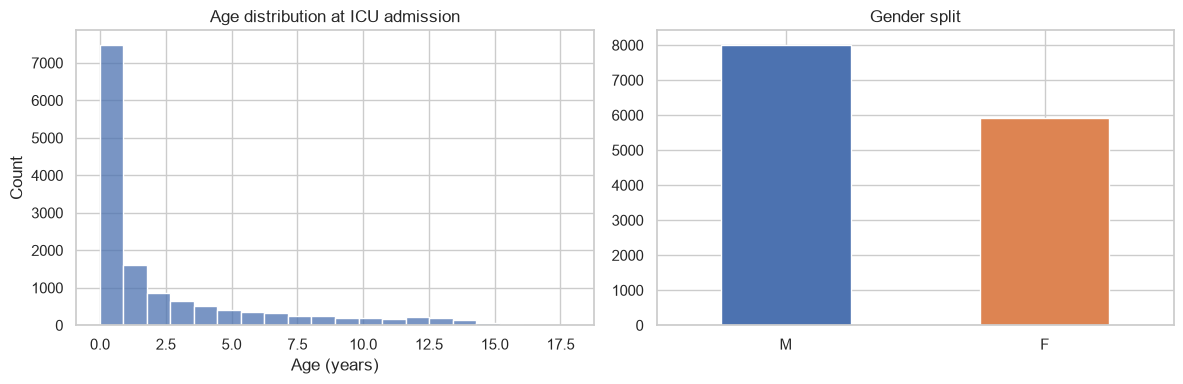

Share of ICU admissions by age group:
age_group
Infant (1-12mo)         32.6
Child (3-12yr)          22.9
Neonate (<1mo)          22.8
Toddler (1-3yr)         17.7
Adolescent (12-18yr)     4.0
Name: proportion, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(cohort["age_years"].dropna(), bins=20, ax=axes[0], color="#4C72B0")
axes[0].set_title("Age distribution at ICU admission")
axes[0].set_xlabel("Age (years)")

cohort["GENDER"].value_counts().plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Gender split")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

age_group_pct = (cohort["age_group"].value_counts(normalize=True) * 100).round(1)
print("Share of ICU admissions by age group:")
print(age_group_pct)


## 4. Demand & seasonality

**Why a hospital cares:** if admissions spike predictably by month (e.g. respiratory illness in
winter), staffing and bed-block planning can be proactive rather than reactive. This is one of the
highest-ROI, lowest-effort analytics deliverables — it needs nothing more than a clean admissions
timestamp field.


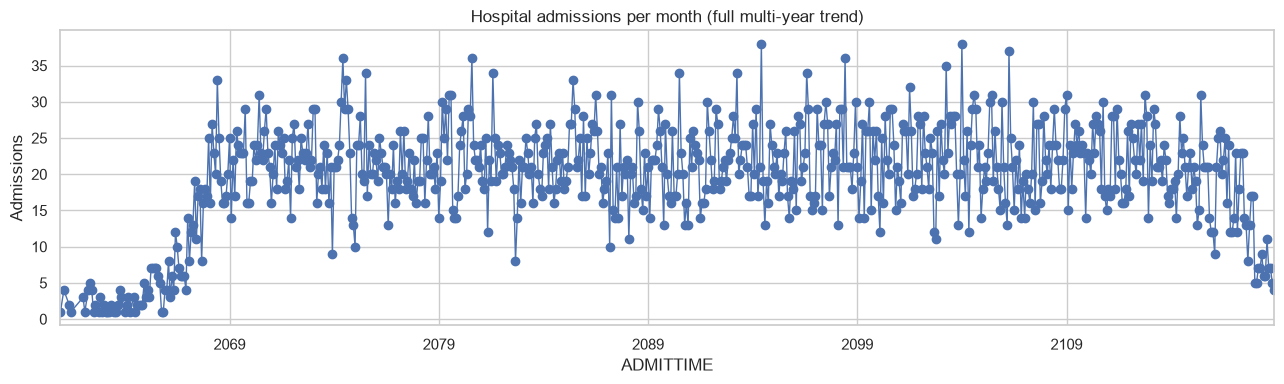

FIRST_CAREUNIT,CICU,General ICU,NICU,PICU,SICU
admit_season,,,,,
Spring,703,715,818,581,803
Summer,875,724,856,598,784
Autumn,636,667,775,493,664
Winter,589,682,833,494,651


In [6]:
monthly = admissions.groupby(admissions["ADMITTIME"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(13, 4))
monthly.plot(ax=ax, marker="o", color="#4C72B0", linewidth=1)
ax.set_title("Hospital admissions per month (full multi-year trend)")
ax.set_ylabel("Admissions")
plt.tight_layout()
plt.show()

season_unit = pd.crosstab(cohort["admit_season"], cohort["FIRST_CAREUNIT"])
season_order = ["Spring", "Summer", "Autumn", "Winter"]
season_unit = season_unit.reindex(season_order)
season_unit


## 5. Length-of-stay (LOS) analytics

**Why a hospital cares:** LOS is the single biggest driver of bed occupancy and cost-per-case.
Unit-level and age-group-level LOS benchmarks let a hospital flag outlier services (e.g. a care
unit with unusually long stays that might indicate a discharge-planning bottleneck, not just
sicker patients).


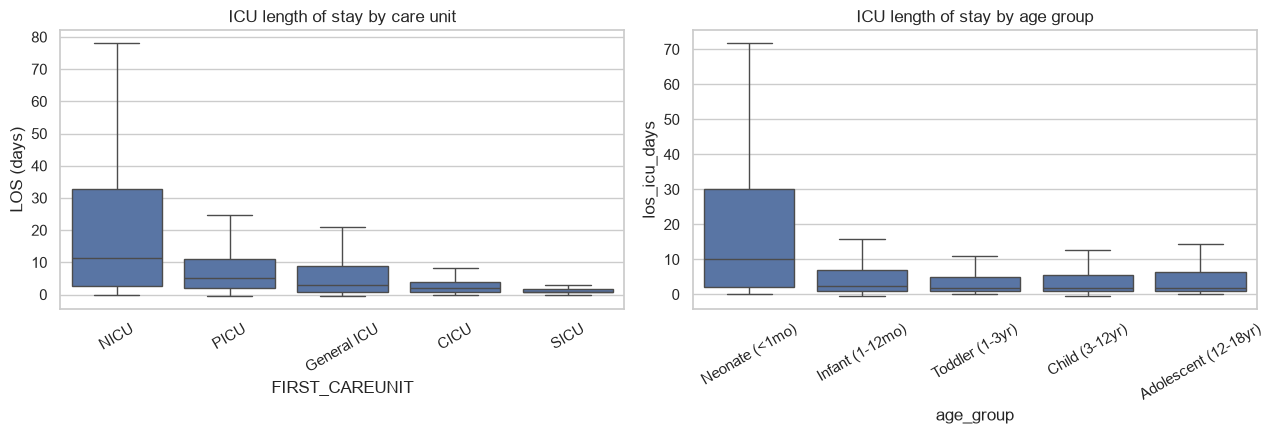

Median ICU LOS by unit (days):
FIRST_CAREUNIT
NICU           11.31
PICU            5.15
General ICU     3.08
CICU            1.90
SICU            0.94
Name: los_icu_days, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = cohort.groupby("FIRST_CAREUNIT")["los_icu_days"].median().sort_values(ascending=False).index
sns.boxplot(data=cohort, x="FIRST_CAREUNIT", y="los_icu_days", order=order, ax=axes[0], showfliers=False)
axes[0].set_title("ICU length of stay by care unit")
axes[0].set_ylabel("LOS (days)")
axes[0].tick_params(axis="x", rotation=30)

age_order = ["Neonate (<1mo)", "Infant (1-12mo)", "Toddler (1-3yr)", "Child (3-12yr)", "Adolescent (12-18yr)"]
sns.boxplot(data=cohort, x="age_group", y="los_icu_days", order=age_order, ax=axes[1], showfliers=False)
axes[1].set_title("ICU length of stay by age group")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print("Median ICU LOS by unit (days):")
print(cohort.groupby("FIRST_CAREUNIT")["los_icu_days"].median().round(2).sort_values(ascending=False))


## 6. Outcome / mortality analytics

**Why a hospital cares:** this is the credibility backbone of any NICU/PICU marketing claim.
Crude (unadjusted) mortality by unit and age group is the starting point; the natural next
deliverable is layering in a severity score (PIM3/PRISM III) at admission so mortality can be
reported as **observed-vs-expected**, which is what actually stands up to peer benchmarking.


Overall crude in-hospital mortality: 7.22%  (971 deaths / 13,449 admissions)\n
By care unit:


,admissions,deaths,mortality_rate_%
FIRST_CAREUNIT,,,
General ICU,2788,424,15.21
PICU,2166,208,9.60
NICU,3282,247,7.53
CICU,2803,59,2.10
SICU,2902,61,2.10


\nBy age group:


,admissions,deaths,mortality_rate_%
age_group,,,
Neonate (<1mo),3185,262,8.23
Infant (1-12mo),4542,341,7.51
Toddler (1-3yr),2467,158,6.40
Child (3-12yr),3195,203,6.35
Adolescent (12-18yr),552,35,6.34


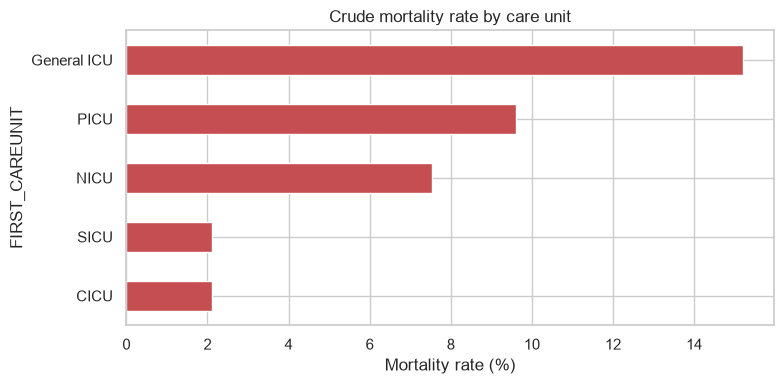

In [8]:
mortality_by_unit = cohort.groupby("FIRST_CAREUNIT")["HOSPITAL_EXPIRE_FLAG"].agg(
    admissions="count", deaths="sum"
)
mortality_by_unit["mortality_rate_%"] = (
    mortality_by_unit["deaths"] / mortality_by_unit["admissions"] * 100
).round(2)

mortality_by_age = cohort.groupby("age_group")["HOSPITAL_EXPIRE_FLAG"].agg(
    admissions="count", deaths="sum"
)
mortality_by_age["mortality_rate_%"] = (
    mortality_by_age["deaths"] / mortality_by_age["admissions"] * 100
).round(2)

overall_rate = admissions["HOSPITAL_EXPIRE_FLAG"].mean() * 100
print(f"Overall crude in-hospital mortality: {overall_rate:.2f}%  "
      f"({admissions['HOSPITAL_EXPIRE_FLAG'].sum():,} deaths / {len(admissions):,} admissions)\\n")

print("By care unit:")
display(mortality_by_unit.sort_values("mortality_rate_%", ascending=False))
print("\\nBy age group:")
display(mortality_by_age.reindex(age_order).sort_values("mortality_rate_%", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
mortality_by_unit["mortality_rate_%"].sort_values().plot(kind="barh", ax=ax, color="#C44E52")
ax.set_title("Crude mortality rate by care unit")
ax.set_xlabel("Mortality rate (%)")
plt.tight_layout()
plt.show()


## 7. Diagnosis / disease-burden analytics

**Why a hospital cares:** case-mix drives equipment and specialist-staffing decisions (ventilators,
dialysis, cardiac monitoring). Since no diagnosis dictionary table was available in this file set,
we group ICD-10 codes by **chapter** (the leading letter, e.g. `J` = respiratory, `Q` = congenital
malformations) — a standard technique for interpreting diagnosis data when a full code dictionary
isn't available yet.


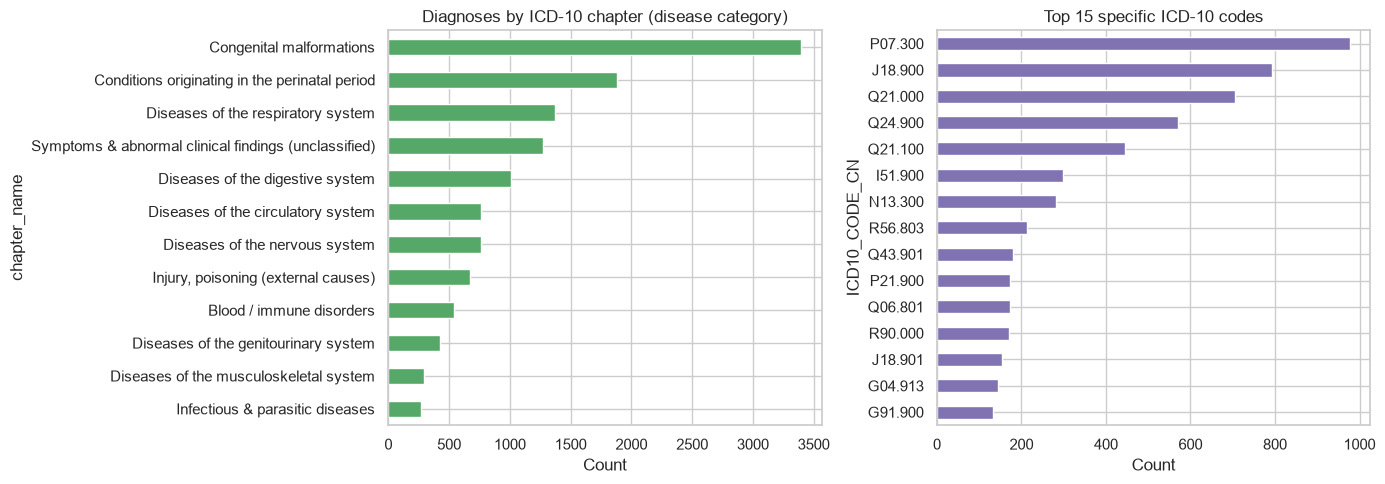

In [9]:
icd10_chapters = {
    "A": "Infectious & parasitic diseases", "B": "Infectious & parasitic diseases",
    "C": "Neoplasms", "D": "Blood / immune disorders",
    "E": "Endocrine, nutritional & metabolic diseases",
    "F": "Mental & behavioural disorders",
    "G": "Diseases of the nervous system",
    "H": "Diseases of eye / ear",
    "I": "Diseases of the circulatory system",
    "J": "Diseases of the respiratory system",
    "K": "Diseases of the digestive system",
    "L": "Diseases of the skin",
    "M": "Diseases of the musculoskeletal system",
    "N": "Diseases of the genitourinary system",
    "O": "Pregnancy, childbirth & the puerperium",
    "P": "Conditions originating in the perinatal period",
    "Q": "Congenital malformations",
    "R": "Symptoms & abnormal clinical findings (unclassified)",
    "S": "Injury, poisoning (external causes)", "T": "Injury, poisoning (external causes)",
    "Z": "Factors influencing health status / contact with services",
}

diagnoses["chapter_code"] = diagnoses["ICD10_CODE_CN"].astype(str).str[0].str.upper()
diagnoses["chapter_name"] = diagnoses["chapter_code"].map(icd10_chapters).fillna("Other / uncoded")

top_chapters = diagnoses["chapter_name"].value_counts().head(12)
top_codes = diagnoses["ICD10_CODE_CN"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_chapters.sort_values().plot(kind="barh", ax=axes[0], color="#55A868")
axes[0].set_title("Diagnoses by ICD-10 chapter (disease category)")
axes[0].set_xlabel("Count")

top_codes.sort_values().plot(kind="barh", ax=axes[1], color="#8172B2")
axes[1].set_title("Top 15 specific ICD-10 codes")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()
